# v4 — Embedding dan retrieval

Ekstrak embedding, ukur retrieval, buat index katalog, dan ekspor ONNX. Jalankan di Colab.

## 1. Setup

In [1]:
# === SETUP (Colab ATAU laptop) ===
import os, sys, json, zipfile, subprocess, importlib.util
from pathlib import Path

QUICK_N = None      # None = penuh. Isi angka kecil (mis. 60) utk uji cepat di CPU -> hasil ke folder "*_quick"
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PAKET = Path('/content/drive/MyDrive/galeria_colab')
    HASIL = Path('/content/drive/MyDrive/galeria_v4_colab/standard')
    WORK = Path('/content/ml_v4e')
    for z in ('galeria_data_v2.zip', 'galeria_code_v2.zip'):
        assert (PAKET / z).exists(), f'{PAKET / z} belum ada -- upload dulu ke Drive'
    assert (HASIL / 'checkpoints' / 'best.pth').exists(), f'{HASIL}/checkpoints/best.pth belum ada'
    if not (WORK / 'src').exists():
        WORK.mkdir(parents=True, exist_ok=True)
        for z in ('galeria_code_v2.zip', 'galeria_data_v2.zip'):
            print('ekstrak', z, '...')
            with zipfile.ZipFile(PAKET / z) as f:
                f.extractall(WORK)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyyaml', 'faiss-cpu', 'onnx', 'onnxruntime', 'onnxscript'], check=False)
    ROOT = WORK
    CKPT_PATH = HASIL / 'checkpoints' / 'best.pth'
    OUT_DIR, CACHE_DIR, EXPORT_DIR = HASIL / 'outputs_02', HASIL / 'data_cache', HASIL / 'export'
else:
    _p = Path.cwd()
    while not ((_p / "src").is_dir() and (_p / "configs").is_dir()):
        if _p == _p.parent:
            raise RuntimeError("folder ml-visual-search/ (berisi src/ & configs/) tidak ketemu")
        _p = _p.parent
    ROOT = _p
    sfx = "_quick" if QUICK_N else ""
    V4 = ROOT / "notebooks/v4_11class/standard"
    CKPT_PATH = V4 / "checkpoints/best.pth"
    OUT_DIR = V4 / f"outputs{sfx}"
    CACHE_DIR = V4 / f"data_cache{sfx}"
    EXPORT_DIR = V4 / f"export{sfx}"
for d in (OUT_DIR, CACHE_DIR, EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

torch.backends.cudnn.benchmark = True
print("colab:", IN_COLAB, "| root:", ROOT)
print("checkpoint:", CKPT_PATH, "| ada:", CKPT_PATH.exists())
print("hasil ke  :", OUT_DIR, "|", CACHE_DIR, "|", EXPORT_DIR)
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| QUICK_N:", QUICK_N)

Mounted at /content/drive
ekstrak galeria_code_v2.zip ...
ekstrak galeria_data_v2.zip ...
colab: True | root: /content/ml_v4e
checkpoint: /content/drive/MyDrive/galeria_v4_colab/standard/checkpoints/best.pth | ada: True
hasil ke  : /content/drive/MyDrive/galeria_v4_colab/standard/outputs_02 | /content/drive/MyDrive/galeria_v4_colab/standard/data_cache | /content/drive/MyDrive/galeria_v4_colab/standard/export
torch: 2.11.0+cu130 | CUDA: True | QUICK_N: None


In [2]:
# === SIAPKAN split v4 `standard` (sama persis dengan run training) ===
# = split v2 dibatasi 11 kelas, minus 12 gambar hampir seragam (hasil audit data). Hasil run: 20764 / 4450 / 4449.
V1_KELAS = ["Art_Nouveau", "Baroque", "Cubism", "Expressionism", "Impressionism", "Naive_Art_Primitivism",
            "Northern_Renaissance", "Post_Impressionism", "Realism", "Romanticism", "Symbolism"]
GAMBAR_SERAGAM = {"wikiart_29040.jpg", "wikiart_16735.jpg", "wikiart_15791.jpg", "wikiart_01682.jpg", "wikiart_28527.jpg",
                   "wikiart_30460.jpg", "wikiart_16411.jpg", "wikiart_21238.jpg", "wikiart_23684.jpg", "wikiart_16484.jpg",
                   "wikiart_16754.jpg", "wikiart_16582.jpg"}
raw_dir_ = Path("data/raw")
_sizes = {}
for s in ("train", "val", "test"):
    d = pd.read_csv(raw_dir_ / f"{s}_split.csv")
    d = d[d["style_name"].isin(V1_KELAS) & ~d["filename"].isin(GAMBAR_SERAGAM)].reset_index(drop=True)
    d.to_csv(raw_dir_ / f"v4_{s}_split.csv", index=False)
    _sizes[s] = len(d)
print(_sizes, "(run training: 20764 / 4450 / 4449)")
assert _sizes == {"train": 20764, "val": 4450, "test": 4449}, "ukuran split tidak cocok dgn run training!"

{'train': 20764, 'val': 4450, 'test': 4449} (run training: 20764 / 4450 / 4449)


In [3]:
from src.utils import set_seed, get_device, resolve_path
from src.dataset import WikiArtDataset
from src.transforms import build_eval_transforms
from src.model import build_model, load_checkpoint
from src.embedding import (extract_embeddings, save_embedding_index, nearest_neighbors,
                           evaluate_retrieval, chance_recall_at_k)
from torch.utils.data import DataLoader

CKPT = str(CKPT_PATH)

# checkpoint ini menyimpan config & label_to_idx SENDIRI (snapshot training v2) --
# sengaja TIDAK load configs/config.yaml yang sekarang (sudah diarahkan ke
# checkpoints/continued_training/ utk training lanjutan).
_raw = torch.load(CKPT, map_location="cpu", weights_only=False)
cfg = _raw["config"]
cfg["train"]["num_workers"] = 0
set_seed(cfg["seed"])
device = get_device(cfg["device"])

label_to_idx = _raw["label_to_idx"]
idx_to_label = {v: k for k, v in label_to_idx.items()}
num_classes = len(label_to_idx)
MEAN = torch.tensor(cfg["image"]["mean"]).view(3, 1, 1)
STD  = torch.tensor(cfg["image"]["std"]).view(3, 1, 1)
def denorm(t): return (t * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

model = build_model(cfg, num_classes=num_classes).to(device)
ck = load_checkpoint(model, CKPT, map_location=str(device))
vm = ck["val_metrics"]
print(f"[MODEL v4 -- 11 kelas] {model.arch} | emb_dim {model.embedding_dim} | checkpoint epoch {ck.get('epoch')} "
      f"| val_macro_f1={vm['macro_f1']:.4f}")
print("  (best.pth = bobot EMA epoch 30, val macro-F1 0.7524; test macro-F1 0.748)")

Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:00<00:00, 212MB/s]


[MODEL v4 -- 11 kelas] convnext_small | emb_dim 768 | checkpoint epoch 30 | val_macro_f1=0.7524
  (best.pth = bobot EMA epoch 30, val macro-F1 0.7524; test macro-F1 0.748)


## 2. Ekstrak embedding: gallery (train+val) vs query (test)

In [4]:
eval_tf = build_eval_transforms(cfg)

def make_ds(split):
    ds = WikiArtDataset(
        csv_path=cfg["data"][f"{split}_csv"], image_dir=cfg["data"]["image_dir"],
        label_column=cfg["data"]["label_column"], label_to_idx=label_to_idx,
        transform=eval_tf, filename_column=cfg["data"]["filename_column"],
    )
    if QUICK_N:
        ds.df = ds.df.sample(min(QUICK_N, len(ds.df)), random_state=0).reset_index(drop=True)
    return ds

emb_bs = cfg["embedding"]["batch_size"]
splits = {s: make_ds(s) for s in ("train", "val", "test")}
loaders_eval = {s: DataLoader(ds, batch_size=emb_bs, shuffle=False, num_workers=0)
               for s, ds in splits.items()}

embs, labs, fnames = {}, {}, {}
for s, ld in loaders_eval.items():
    e, l = extract_embeddings(model, ld, device,
                          l2_normalize=cfg["embedding"]["l2_normalize"], desc=f"embed:{s}")
    embs[s], labs[s] = e, l
    fnames[s] = splits[s].df[cfg["data"]["filename_column"]].tolist()
    print(f"{s:5s}: {e.shape[0]} gambar -> embedding {e.shape[1]}-d")

gallery_emb    = np.concatenate([embs["train"], embs["val"]], axis=0)
gallery_labels = np.concatenate([labs["train"], labs["val"]], axis=0)
gallery_fnames = fnames["train"] + fnames["val"]
query_emb, query_labels, query_fnames = embs["test"], labs["test"], fnames["test"]
print(f"\ngallery (train+val): {len(gallery_labels)} | query (test): {len(query_labels)}")

train: 20764 gambar -> embedding 768-d


val  : 4450 gambar -> embedding 768-d


test : 4449 gambar -> embedding 768-d

gallery (train+val): 25214 | query (test): 4449


## 3. Recall@k / Precision@k / mAP@k — metrik sukses Visual Search

   k |   Recall@k |   chance |  Precision@k |    mAP@k
   1 |      0.751 |    0.139 |        0.751 |    0.751
   5 |      0.835 |    0.485 |        0.742 |    0.777
  10 |      0.862 |    0.687 |        0.741 |    0.772


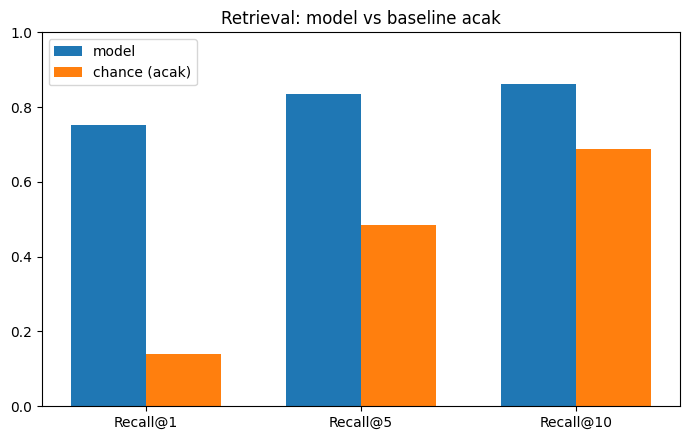

535

In [5]:
KS = (1, 5, 10)
metrics = evaluate_retrieval(query_emb, query_labels, gallery_emb, gallery_labels, ks=KS)
chance = {k: chance_recall_at_k(gallery_labels, k) for k in KS}

print(f"{'k':>4} | {'Recall@k':>10} | {'chance':>8} | {'Precision@k':>12} | {'mAP@k':>8}")
for k in KS:
    print(f"{k:4d} | {metrics[f'recall@{k}']:10.3f} | {chance[k]:8.3f} | "
          f"{metrics[f'precision@{k}']:12.3f} | {metrics[f'map@{k}']:8.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(KS)); w = 0.35
ax.bar(x - w/2, [metrics[f"recall@{k}"] for k in KS], w, label="model")
ax.bar(x + w/2, [chance[k] for k in KS], w, label="chance (acak)")
ax.set_xticks(x, [f"Recall@{k}" for k in KS]); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Retrieval: model vs baseline acak"); plt.tight_layout(); plt.show()

(OUT_DIR / "retrieval_metrics.json").write_text(
    json.dumps({"metrics": metrics, "chance": chance,
               "checkpoint": {"epoch": ck.get("epoch"), "monitor_value": ck.get("monitor_value")}},
              indent=2), encoding="utf-8")

## 4. Contoh nyata: 1 query -> top-5 hasil (yang dilihat user)

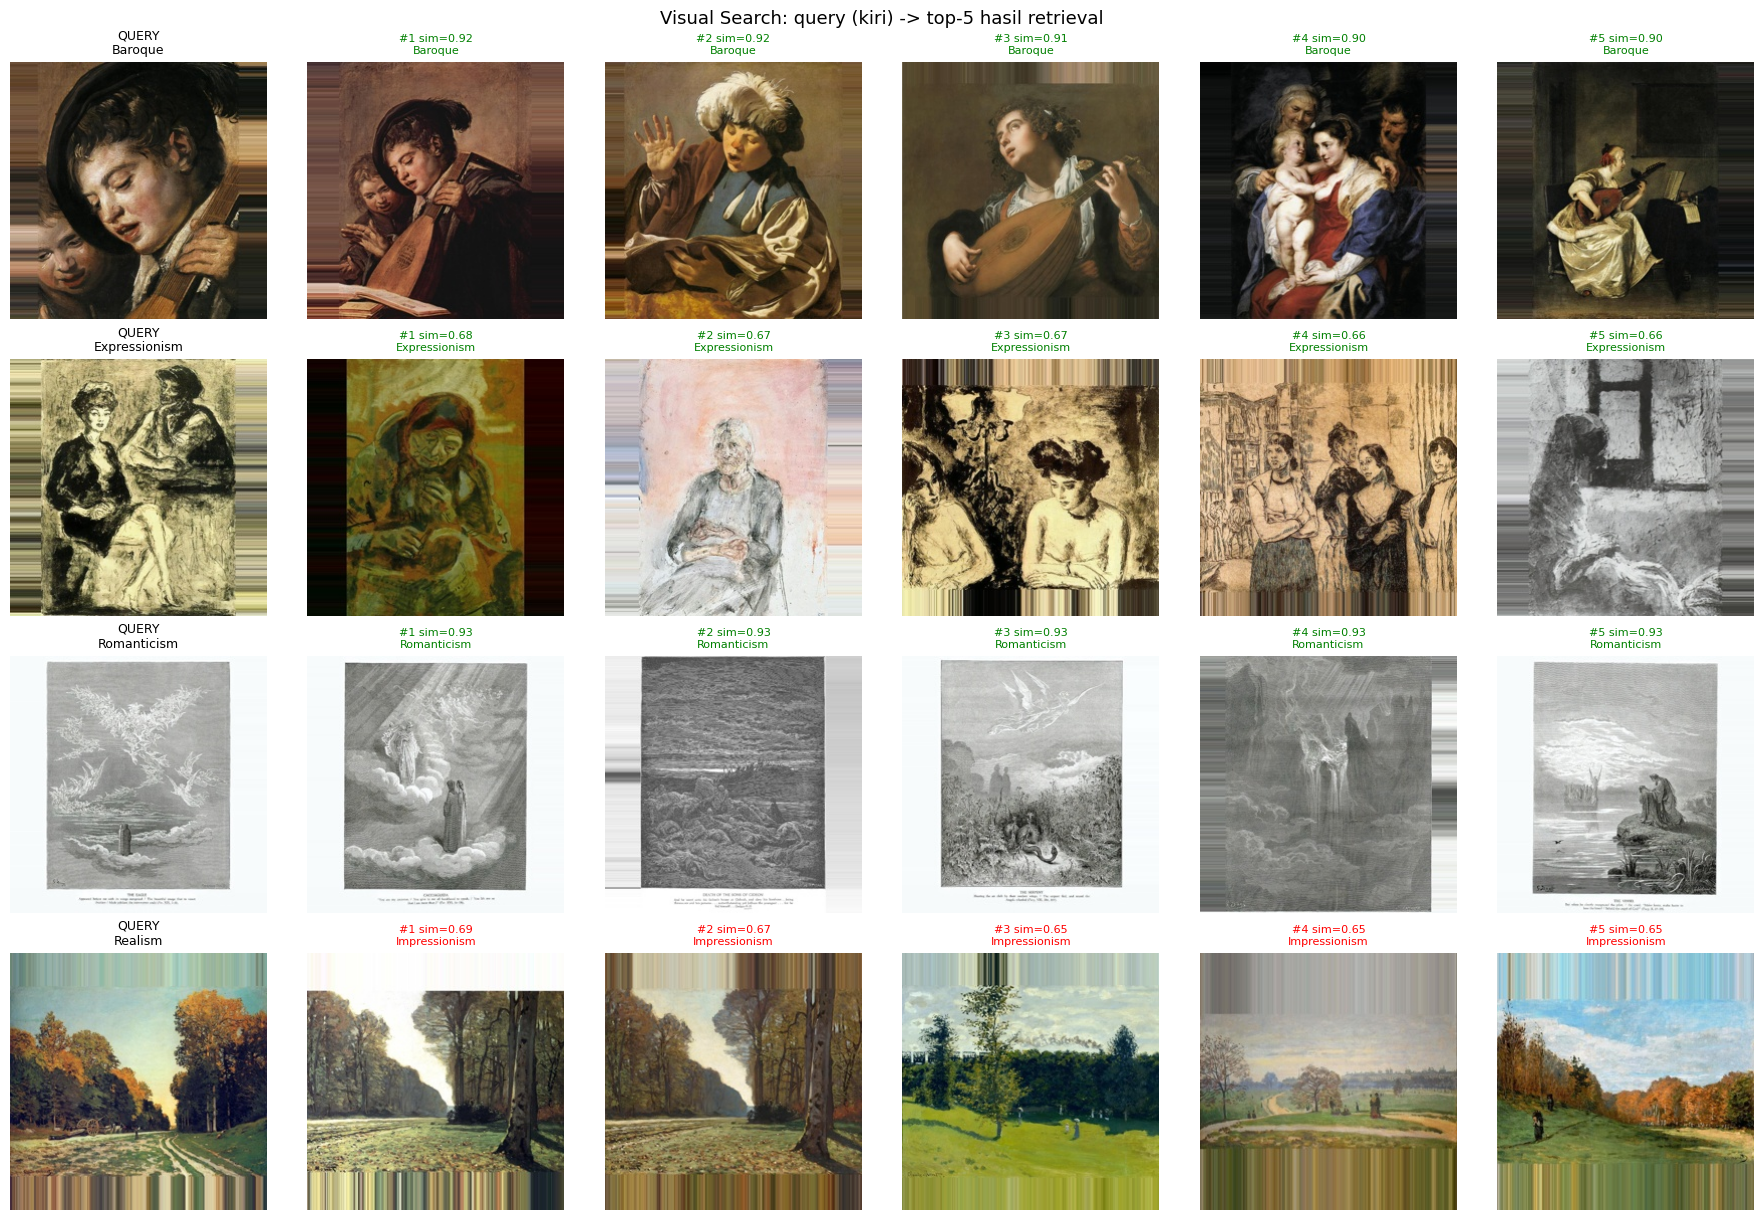

In [6]:
rng = np.random.default_rng(cfg["seed"])
n_show = 4
q_idx = rng.choice(len(query_labels), size=n_show, replace=False)
idx, scores = nearest_neighbors(query_emb[q_idx], gallery_emb, top_k=5)

fig, axes = plt.subplots(n_show, 6, figsize=(18, 3.1 * n_show))
raw_dir = resolve_path(cfg["data"]["image_dir"])
from PIL import Image
for r, qi in enumerate(q_idx):
    qimg = Image.open(raw_dir / query_fnames[qi]).convert("RGB")
    axes[r, 0].imshow(qimg); axes[r, 0].set_title(f"QUERY\n{idx_to_label[query_labels[qi]]}", fontsize=9)
    axes[r, 0].axis("off")
    for c in range(5):
        gi = idx[r, c]
        gimg = Image.open(raw_dir / gallery_fnames[gi]).convert("RGB")
        ok = gallery_labels[gi] == query_labels[qi]
        axes[r, c+1].imshow(gimg)
        axes[r, c+1].set_title(f"#{c+1} sim={scores[r,c]:.2f}\n{idx_to_label[gallery_labels[gi]]}",
                               fontsize=8, color="green" if ok else "red")
        axes[r, c+1].axis("off")
fig.suptitle("Visual Search: query (kiri) -> top-5 hasil retrieval", fontsize=13)
plt.tight_layout(); plt.savefig((OUT_DIR / "retrieval_examples.png"), dpi=100); plt.show()

## 5. Index embedding seluruh katalog (untuk `backend/`)

In [7]:
REGEN_OUTPUT_PATH = str(CACHE_DIR / "catalog_embeddings_regenerated.npz")

catalog_ds = WikiArtDataset(
    csv_path=cfg["embedding"]["source_csv"], image_dir=cfg["data"]["image_dir"],
    label_column=cfg["data"]["label_column"], label_to_idx=label_to_idx,
    transform=eval_tf, filename_column=cfg["data"]["filename_column"],
)
_img_dir = resolve_path(cfg["data"]["image_dir"])
_ok = catalog_ds.df[cfg["data"]["filename_column"]].map(lambda f: (_img_dir / f).exists())
print(f"katalog: {int(_ok.sum())} gambar tersedia dari {len(_ok)} di metadata ({int((~_ok).sum())} tidak ada di paket data -> dilewati)")
catalog_ds.df = catalog_ds.df[_ok].reset_index(drop=True)
if QUICK_N:
    catalog_ds.df = catalog_ds.df.sample(min(QUICK_N * 3, len(catalog_ds.df)), random_state=0).reset_index(drop=True)
catalog_loader = DataLoader(catalog_ds, batch_size=cfg["embedding"]["batch_size"],
                           shuffle=False, num_workers=0)
cat_emb, cat_labels = extract_embeddings(model, catalog_loader, device,
                                         l2_normalize=cfg["embedding"]["l2_normalize"],
                                         desc="embed:katalog")
cat_fnames = catalog_ds.df[cfg["data"]["filename_column"]].tolist()
save_embedding_index(cat_emb, cat_fnames, cat_labels, REGEN_OUTPUT_PATH)
print(f"[REGENERATED] index katalog v4: {cat_emb.shape[0]} gambar x {cat_emb.shape[1]}-d -> "
      f"{REGEN_OUTPUT_PATH} (TIDAK menimpa live/backup asli)")
print(f"  ({int((cat_labels == -1).sum())} di antaranya di luar 11 kelas training, "
      f"tetap ter-embed)")

katalog: 33520 gambar tersedia dari 33937 di metadata (417 tidak ada di paket data -> dilewati)


[REGENERATED] index katalog v4: 33520 gambar x 768-d -> /content/drive/MyDrive/galeria_v4_colab/standard/data_cache/catalog_embeddings_regenerated.npz (TIDAK menimpa live/backup asli)
  (3845 di antaranya di luar 11 kelas training, tetap ter-embed)


## 6. Uji instance retrieval — skenario "scan lukisan" (Google Lens-style)

In [8]:
from src.transforms import build_capture_simulation_transform
from PIL import Image
from tqdm import tqdm

capture_tf = build_capture_simulation_transform(cfg)
raw_dir = resolve_path(cfg["data"]["image_dir"])

N_QUERY = min(150, len(cat_fnames))
BATCH = 32
rng2 = np.random.default_rng(cfg["seed"])
query_idx = rng2.choice(len(cat_fnames), size=N_QUERY, replace=False)

sim_embs = []
with torch.no_grad():
    for start in tqdm(range(0, N_QUERY, BATCH), desc="simulasi foto HP"):
        batch_idx = query_idx[start:start + BATCH]
        imgs = [capture_tf(Image.open(raw_dir / cat_fnames[qi]).convert("RGB")) for qi in batch_idx]
        x = torch.stack(imgs).to(device)
        f = model.forward_features(x)
        if cfg["embedding"]["l2_normalize"]:
            f = torch.nn.functional.normalize(f, dim=1)
        sim_embs.append(f.cpu().numpy())
sim_embs = np.concatenate(sim_embs, axis=0)

# cari di SELURUH katalog (termasuk gambar aslinya sendiri -> itu yg diharapkan ketemu)
idxs, scores = nearest_neighbors(sim_embs, cat_emb, top_k=10)

hit1  = idxs[:, 0] == query_idx
hit5  = (idxs[:, :5]  == query_idx[:, None]).any(axis=1)
hit10 = (idxs[:, :10] == query_idx[:, None]).any(axis=1)
print(f"Instance retrieval (n={N_QUERY} simulasi 'foto HP'):")
print(f"  top-1 : {hit1.mean():.3f}")
print(f"  top-5 : {hit5.mean():.3f}")
print(f"  top-10: {hit10.mean():.3f}")

(OUT_DIR / "instance_retrieval_metrics.json").write_text(
    json.dumps({"n_query": N_QUERY, "top1": float(hit1.mean()),
               "top5": float(hit5.mean()), "top10": float(hit10.mean())},
              indent=2), encoding="utf-8")

simulasi foto HP: 100%|██████████| 5/5 [00:03<00:00,  1.25it/s]

Instance retrieval (n=150 simulasi 'foto HP'):
  top-1 : 0.853
  top-5 : 0.893
  top-10: 0.933


111

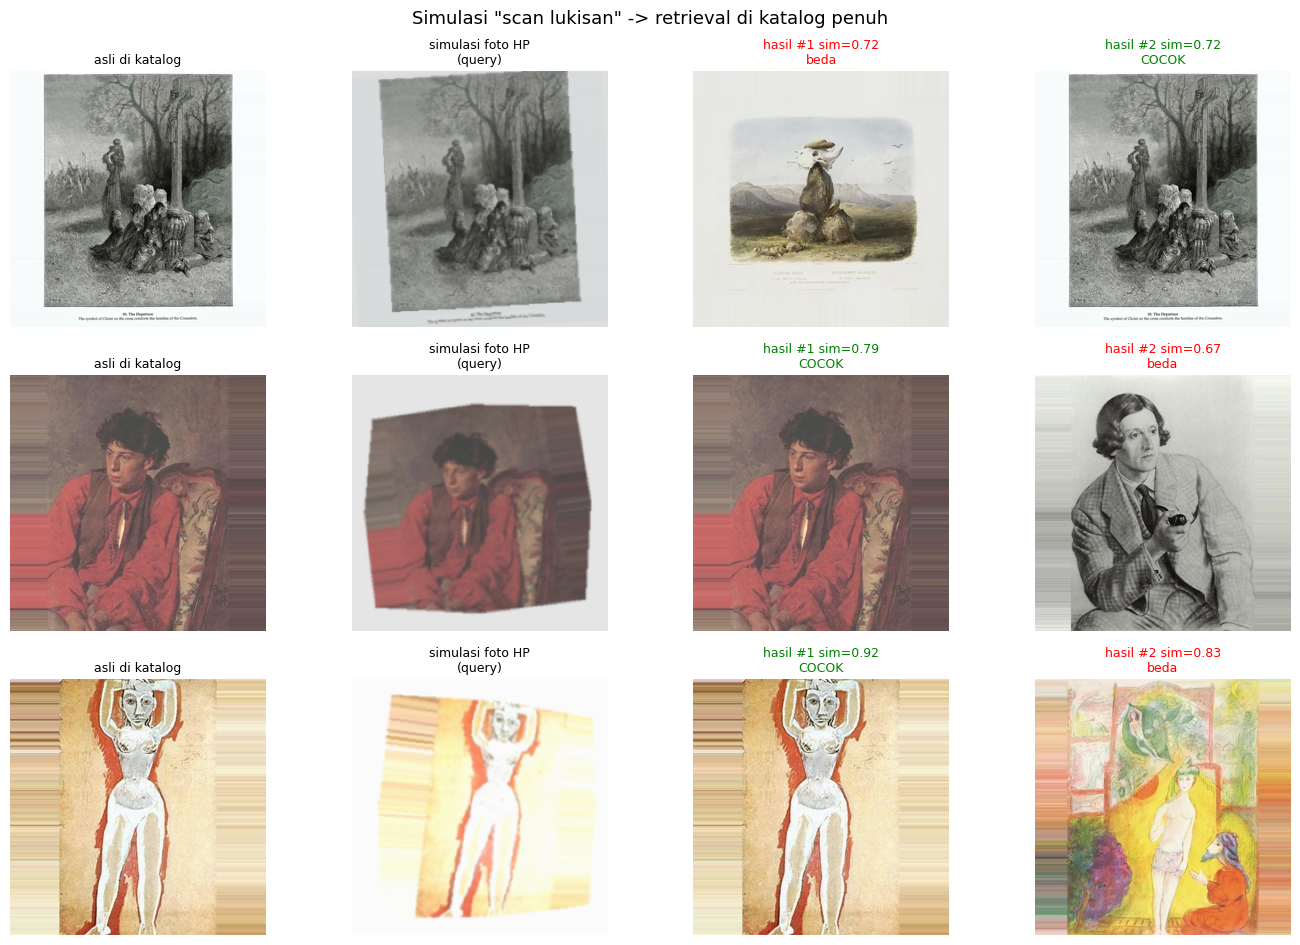

In [9]:
show_n = 3
fig, axes = plt.subplots(show_n, 4, figsize=(14, 3.2 * show_n))
for r in range(show_n):
    qi = query_idx[r]
    orig = Image.open(raw_dir / cat_fnames[qi]).convert("RGB")
    photo_tensor = capture_tf(Image.open(raw_dir / cat_fnames[qi]).convert("RGB"))
    axes[r, 0].imshow(orig); axes[r, 0].set_title("asli di katalog", fontsize=9); axes[r, 0].axis("off")
    axes[r, 1].imshow(denorm(photo_tensor)); axes[r, 1].set_title("simulasi foto HP\n(query)", fontsize=9)
    axes[r, 1].axis("off")
    for c in range(2):
        gi = idxs[r, c]
        gimg = Image.open(raw_dir / cat_fnames[gi]).convert("RGB")
        ok = gi == qi
        axes[r, 2 + c].imshow(gimg)
        axes[r, 2 + c].set_title(f"hasil #{c+1} sim={scores[r,c]:.2f}\n{'COCOK' if ok else 'beda'}",
                                 fontsize=9, color="green" if ok else "red")
        axes[r, 2 + c].axis("off")
fig.suptitle('Simulasi "scan lukisan" -> retrieval di katalog penuh', fontsize=13)
plt.tight_layout(); plt.savefig((OUT_DIR / "instance_retrieval_examples.png"), dpi=100); plt.show()

## 7. Export ke TorchScript / ONNX (untuk `backend/`)

In [10]:

# === EKSPOR 2-output (embedding + style_probs) -- format yang dipakai backend ===
from src.export import EmbeddingAndStyleWrapper, export_torchscript, export_onnx

model = model.cpu().eval()
export_model = EmbeddingAndStyleWrapper(model, l2_normalize=cfg["embedding"]["l2_normalize"]).eval()
example = torch.randn(1, 3, cfg["image"]["size"], cfg["image"]["size"])
ts_path, onnx_path = str(EXPORT_DIR / "model.torchscript"), str(EXPORT_DIR / "model.onnx")

diff_ts = export_torchscript(export_model, example, ts_path)
print(f"TorchScript -> {ts_path}  (selisih vs PyTorch: {diff_ts:.2e})")
diff_onnx = export_onnx(export_model, example, onnx_path, cfg["export"]["onnx_opset"], ["embedding", "style_probs"])
if diff_onnx is None:
    print(f"ONNX -> {onnx_path}  (onnxruntime tidak ada, verifikasi dilewati)")
else:
    print(f"ONNX -> {onnx_path}  (selisih vs PyTorch: {diff_onnx:.2e})")
ok = diff_ts < 1e-4 and (diff_onnx is None or diff_onnx < 1e-4)
print("VERIFIKASI OK -- siap dipakai backend/" if ok else "[!] selisih > 1e-4, cek ulang")

# peta label (backend: VS_LABEL_MAP_PATH) -- urutan kelas HARUS sama dengan output style_probs
(EXPORT_DIR / "label_to_idx__style_name.json").write_text(json.dumps(label_to_idx, indent=2, ensure_ascii=False), encoding="utf-8")
print("peta label ->", EXPORT_DIR / "label_to_idx__style_name.json", "| kelas:", len(label_to_idx))


TorchScript -> /content/drive/MyDrive/galeria_v4_colab/standard/export/model.torchscript  (selisih vs PyTorch: 0.00e+00)
ONNX -> /content/drive/MyDrive/galeria_v4_colab/standard/export/model.onnx  (selisih vs PyTorch: 1.34e-07)
VERIFIKASI OK -- siap dipakai backend/
peta label -> /content/drive/MyDrive/galeria_v4_colab/standard/export/label_to_idx__style_name.json | kelas: 11
